# Reprojeter un lot vectoriel avec un rapport par couche
**Cartomize · Module M09 / G04 · Sources 1.6.0**

Durée indicative : 30 minutes.

Ce cours rassemble des couches contenues dans plusieurs fichiers, examine les transformations disponibles, puis reprojette le lot entier. Chaque couche conserve ses attributs et reçoit un GeoPackage, un identifiant stable et une description de la transformation réellement utilisée.

Les sites, zones et axes sont **simulés**, placés près du Mayombe pour cet exercice. Ils ne correspondent à aucun relevé de terrain. Les deux couches du GeoPackage ont volontairement des SCR différents. Le cours reste autonome, sans téléchargement géographique ni installation de QGIS.

Suivre le [guide d’installation](../README.md), puis exécuter toutes les cellules. Les contrôles portent sur les coordonnées, les attributs, les emprises, les fichiers enregistrés et une chaîne réutilisable.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import Point, LineString, box
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "course.py").is_file() or (p / "tutorials/course.py").is_file())
root = root if (root / "course.py").is_file() else root / "tutorials"
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from course import run_directory
import cartomize as cm

out = run_directory("15_reprojection_vectorielle_par_lot")
inputs = out / "entrees"
inputs.mkdir()
TARGET = "EPSG:3857"

def webmerc(xy):
    angles = np.deg2rad(np.asarray(xy, dtype="float64")[:, :2])
    return np.column_stack((6378137.0 * angles[:, 0],
                            6378137.0 * np.log(np.tan(np.pi / 4 + angles[:, 1] / 2))))

print("Cartomize", cm.__version__, "— nouveau dossier pédagogique :", out.name)

Cartomize 1.6.0 — nouveau dossier pédagogique : 15_reprojection_vectorielle_par_lot_yem2mz44


## 1. Préparer des sources aux SCR différents

Le GeoPackage `territoire.gpkg` contient deux couches : les sites en **WGS 84, EPSG:4326**, et les zones en **UTM 33 sud, EPSG:32733**. Un GeoJSON séparé contient un axe en WGS 84. Les couches sont conservées séparément : la reprojection n'est pas une fusion de tables.

Les données WGS 84 sont créées en longitude/latitude. `to_crs(32733)` transforme les coordonnées des zones pour construire l'entrée pédagogique projetée ; `set_crs` seul ne réaliserait pas cette transformation.

In [2]:
sites = gpd.GeoDataFrame(
    {"code": ["A", "B", "C"], "nom": ["Site simulé A", "Site simulé B", "Site simulé C"],
     "valeur": [12., np.nan, 28.]},
    geometry=[Point(12.54, -4.21), Point(12.56, -4.19), Point(12.58, -4.18)], crs=4326,
)
zones_wgs84 = gpd.GeoDataFrame(
    {"code": ["Z1", "Z2"], "nom": ["Zone simulée ouest", "Zone simulée est"]},
    geometry=[box(12.535, -4.215, 12.557, -4.185), box(12.56, -4.2, 12.585, -4.175)], crs=4326,
)
axes = gpd.GeoDataFrame(
    {"code": ["L1"], "nom": ["Axe simulé"]},
    geometry=[LineString([(12.535, -4.212), (12.55, -4.2), (12.57, -4.19), (12.585, -4.177)])], crs=4326,
)
package = inputs / "territoire.gpkg"
sites.to_file(package, layer="sites", driver="GPKG", index=False)
zones_wgs84.to_crs(32733).to_file(package, layer="zones", driver="GPKG", index=False)
axes.to_file(inputs / "axes.geojson", driver="GeoJSON", index=False)
originals = {"sites": sites, "zones": zones_wgs84, "axes": axes}

discovered = cm.discover_vector_layers(inputs)
assert len(discovered) == 3
assert sum(layer["features"] for layer in discovered) == 6
display(pd.DataFrame(discovered)[["id", "layer", "features", "source_crs", "bounds"]])

,id,layer,features,source_crs,bounds
0,axes_9d0b8d5cdded,axes,1,EPSG:4326,"[12.535, -4.212, 12.585, -4.177]"
1,sites_9da266ab4245,sites,3,EPSG:4326,"[12.54, -4.21, 12.58, -4.18]"
2,zones_dea6f6a528f1,zones,2,EPSG:32733,"[226349.615068, 9533674.582246, 231908.759514,..."


## 2. Examiner les transformations avant d'écrire

`inspect_reprojection` est en lecture seule. Son catalogue donne, pour chaque couche, les opérations disponibles, leurs identifiants, leur précision annoncée et leurs grilles. L'absence de précision publiée est représentée par `None` ; elle ne doit pas être interprétée comme une erreur de zéro mètre.

Le comportement par défaut exige la meilleure opération disponible selon PROJ et refuse les transformations approximatives dites *ballpark*. Une zone d'intérêt peut aider au classement des opérations ; elle ne découpe pas les données. Les identifiants de couche dépendent du chemin et du nom de couche : les relever après la découverte du lot.

In [3]:
inspection = cm.inspect_reprojection(inputs, TARGET)
rows = []
for layer in inspection["layers"]:
    catalogue = layer["catalogue"]
    assert catalogue["best_available"] and catalogue["operations"]
    for operation in catalogue["operations"]:
        rows.append({"Couche": layer["layer"], "ID de couche": layer["id"],
                     "Opération": operation["description"], "ID d'opération": operation["id"],
                     "Précision annoncée (m)": operation["accuracy"],
                     "Approximation ballpark": operation["ballpark"],
                     "Grilles": len(operation["grids"])})
display(pd.DataFrame(rows))
assert not (out / "lot_reprojete").exists()

,Couche,ID de couche,Opération,ID d'opération,Précision annoncée (m),Approximation ballpark,Grilles
0,axes,axes_9d0b8d5cdded,Popular Visualisation Pseudo-Mercator (with ax...,op_e9864102061d22da72fe,NaN,False,0
1,sites,sites_9da266ab4245,Popular Visualisation Pseudo-Mercator (with ax...,op_e9864102061d22da72fe,NaN,False,0
2,zones,zones_dea6f6a528f1,Inverse of UTM zone 33S + Popular Visualisatio...,op_1f56b0a18da81abb9b07,0.0,False,0


## 3. Reprojeter le lot et lire son bilan

Le dossier final est publié après la réussite de toutes les couches. Une erreur ou une annulation avant cette publication ne laisse pas un lot partiellement livré. Chaque fichier source reste intact.

Les emprises du rapport sont calculées à partir des sommets effectivement enregistrés. Les bornes d'origine sont exprimées dans le SCR de chaque couche ; elles ne sont donc pas directement comparables entre degrés et mètres. Le manifeste conserve aussi la définition complète des SCR et de l'opération utilisée.

In [4]:
result = cm.reproject_batch(inputs, out / "lot_reprojete", TARGET)
assert result.manifest.is_file() and result.report.is_file()
assert len(result.layers) == 3
manifest = json.loads(result.manifest.read_text(encoding="utf-8"))
assert manifest["schema"] == "cartomize.vector_reprojection.v1"
assert manifest["status"] == "complete"
assert manifest["feature_count"] == 6

table = pd.read_csv(result.report)
display(table[["layer", "features", "source_crs", "target_crs", "source_bounds",
               "target_bounds", "selection", "accuracy_m", "ballpark"]])
for layer in manifest["layers"]:
    assert layer["operation"]["definition"]
    assert layer["operation"]["ballpark"] is False
print("Produits publiés :", len(result.layers), "GeoPackage, un CSV et un manifeste JSON")

,layer,features,source_crs,target_crs,source_bounds,target_bounds,selection,accuracy_m,ballpark
0,axes,1,EPSG:4326,EPSG:3857,"[12.535, -4.212, 12.585, -4.177]","[1395389.8170936843, -469300.58487739373, 1400...",automatic,NaN,False
1,sites,3,EPSG:4326,EPSG:3857,"[12.54, -4.21, 12.58, -4.18]","[1395946.4145476504, -469077.34323223075, 1400...",automatic,NaN,False
2,zones,2,EPSG:32733,EPSG:3857,"[226349.61506816407, 9533674.582246173, 231908...","[1395389.8170936843, -469635.44842127716, 1400...",automatic,0.0,False


Produits publiés : 3 GeoPackage, un CSV et un manifeste JSON


## 4. Contrôler les coordonnées par une formule distincte

EPSG:3857 est choisi ici pour disposer d'une référence numérique simple. À partir de la longitude λ et de la latitude φ en radians : **x = Rλ**, **y = R ln(tan(π/4 + φ/2))**, avec **R = 6 378 137 m**. La fonction `webmerc` ci-dessus applique ces équations avec NumPy, sans appeler le moteur de reprojection pour produire la référence.

Les contrôles comparent tous les sommets, les attributs, les effectifs et les emprises. Cette projection sert ici à vérifier la chaîne ; une analyse de superficies doit choisir un SCR approprié à l'étude. [Formules et exemple numérique publiés par PROJ](https://proj.org/en/stable/operations/projections/webmerc.html).

In [5]:
saved = {}
checks = []
for layer in manifest["layers"]:
    name = layer["layer"]
    original = originals[name]
    projected = gpd.read_file(result.layers[layer["id"]])
    saved[name] = projected
    assert projected.crs.to_epsg() == 3857
    assert len(projected) == len(original)
    pd.testing.assert_frame_equal(
        original.drop(columns="geometry"), projected.drop(columns="geometry"),
        check_dtype=False, check_exact=True,
    )
    reference = webmerc(shapely.get_coordinates(original.geometry.to_numpy()))
    observed = shapely.get_coordinates(projected.geometry.to_numpy())
    np.testing.assert_allclose(observed, reference, rtol=0, atol=2e-6)
    np.testing.assert_allclose(layer["target_bounds"], projected.total_bounds, rtol=0, atol=2e-6)
    checks.append({"Couche": name, "Entités conservées": len(projected),
                   "Sommets contrôlés": len(observed),
                   "Écart maximal (m)": float(np.max(np.abs(reference - observed)))})
display(pd.DataFrame(checks))

,Couche,Entités conservées,Sommets contrôlés,Écart maximal (m)
0,axes,1,4,1.338776e-09
1,sites,3,3,1.105946e-09
2,zones,2,10,1.164153e-09


## 5. Réutiliser le choix et poursuivre une couche dans un plan

`operations` associe chaque identifiant de couche à un identifiant d'opération fourni par l'inspection. Un identifiant devenu indisponible provoque un refus explicite ; le logiciel ne lui substitue pas silencieusement une autre transformation.

Dans un plan, le produit nommé `@lot:identifiant_de_couche` permet de poursuivre une couche précise du lot. L'exemple crée des tampons pédagogiques de 100 m autour des sites après la reprojection. Les produits du lot et les tampons sont publiés ensemble à la fin du plan.

In [6]:
selections = {layer["id"]: layer["operation"]["id"] for layer in manifest["layers"]}
selected = cm.reproject_batch(inputs, out / "lot_selection_explicite", TARGET, operations=selections)
assert all(layer["selection"] == "explicit" for layer in selected.summary["layers"])
for identifier, path in selected.layers.items():
    np.testing.assert_array_equal(
        shapely.get_coordinates(gpd.read_file(path).geometry.to_numpy()),
        shapely.get_coordinates(gpd.read_file(result.layers[identifier]).geometry.to_numpy()),
    )

sites_id = next(layer["id"] for layer in discovered if layer["layer"] == "sites")
plan = cm.processing_plan([
    {"id": "lot", "operation": "vector.reproject_batch",
     "parameters": {"sources": str(inputs), "target_crs": TARGET}},
    {"id": "tampons", "operation": "vector.buffer",
     "parameters": {"data": f"@lot:{sites_id}", "distance": 100}},
])
plan_path = cm.run_plan(plan, out / "chaine_reprojection")
record = json.loads(plan_path.read_text(encoding="utf-8"))
assert sites_id in record["products"]["lot"]
buffers = gpd.read_file(record["products"]["tampons"]["primary"])
assert len(buffers) == 3 and buffers.crs.to_epsg() == 3857
assert buffers.geometry.is_valid.all()
print("Choix explicite reproduit ; la chaîne a créé", len(buffers), "tampons.")

Choix explicite reproduit ; la chaîne a créé 3 tampons.


## 6. Vérifier une valeur publiée et un refus attendu

La documentation PROJ indique **(222 638,98 m ; 6 274 861,39 m)** pour **(2° E ; 49° N)** en Web Mercator. La tolérance de 0,01 m correspond à l'arrondi au centimètre de cette référence publiée.

La seconde vérification retire volontairement le SCR d'une copie en mémoire. Le moteur doit refuser le lot entier. Déclarer le SCR correct d'une donnée est une action distincte de la reprojection ; il faut connaître sa référence réelle avant de la déclarer.

In [7]:
control = gpd.GeoDataFrame({"reference": ["Exemple PROJ"]}, geometry=[Point(2, 49)], crs=4326)
control_batch = cm.reproject_batch(control, out / "reference_publiee", TARGET)
point = gpd.read_file(next(iter(control_batch.layers.values()))).geometry.iloc[0]
np.testing.assert_allclose([point.x, point.y], [222638.98, 6274861.39], rtol=0, atol=.01)
print("Référence publiée contrôlée :", round(point.x, 2), round(point.y, 2))

without_crs = sites.copy().set_crs(None, allow_override=True)
refused = out / "lot_sans_scr"
try:
    cm.reproject_batch([str(package), without_crs], refused, TARGET)
except ValueError as error:
    assert not refused.exists()
    print("Refus attendu :", str(error))
else:
    raise AssertionError("Une source sans SCR ne doit pas être acceptée.")

Référence publiée contrôlée : 222638.98 6274861.39
Refus attendu : memory_2 has no CRS. Declare its actual source CRS before processing.


## 7. Lire les coordonnées avant et après

Les deux panneaux représentent les mêmes objets simulés, dans leurs unités respectives. Les attributs et le nombre d'entités restent identiques. Les fichiers finaux contiennent les coordonnées transformées ; la figure n'est pas utilisée pour calculer la référence numérique.

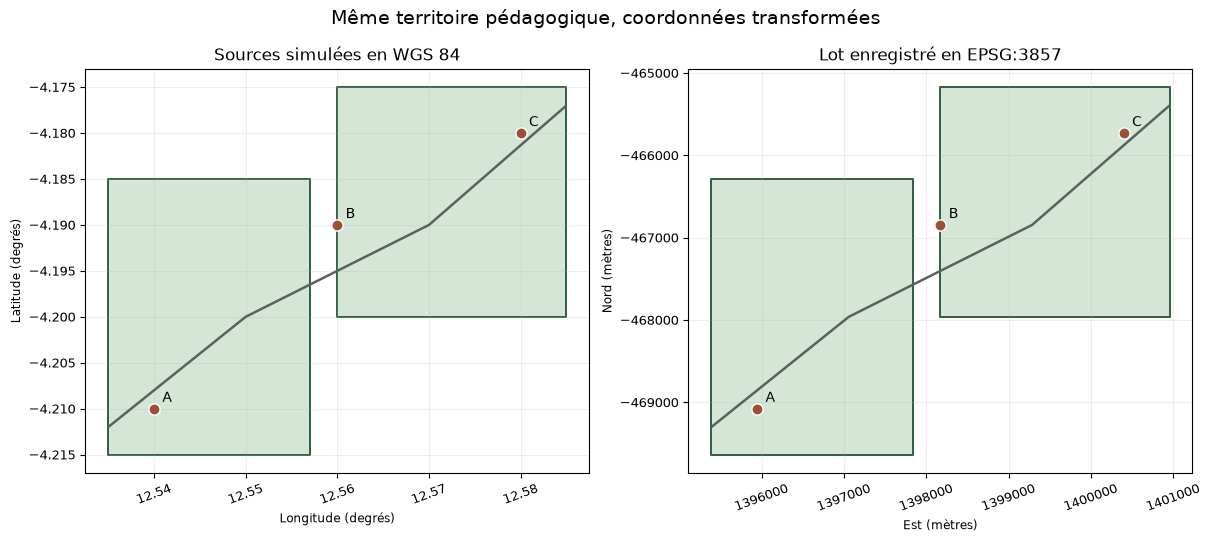

,Couche,Fichier,Entités,Transformation
0,axes,axes_9d0b8d5cdded.gpkg,1,Popular Visualisation Pseudo-Mercator (with ax...
1,sites,sites_9da266ab4245.gpkg,3,Popular Visualisation Pseudo-Mercator (with ax...
2,zones,zones_dea6f6a528f1.gpkg,2,Inverse of UTM zone 33S + Popular Visualisatio...


Manifeste : manifest.json — Bilan : report.csv


In [8]:
fig, axes_plot = plt.subplots(1, 2, figsize=(12, 5.3), layout="constrained")
views = [(zones_wgs84, axes, sites), (saved["zones"], saved["axes"], saved["sites"])]
for ax, (zones_view, lines_view, points_view) in zip(axes_plot, views):
    zones_view.plot(ax=ax, facecolor="#d5e6d7", edgecolor="#315f43", linewidth=1.4)
    lines_view.plot(ax=ax, color="#59625d", linewidth=1.8)
    points_view.plot(ax=ax, color="#9c5036", edgecolor="white", markersize=65, zorder=3)
    for row in points_view.itertuples():
        ax.annotate(row.code, (row.geometry.x, row.geometry.y), xytext=(6, 5), textcoords="offset points")
    ax.grid(alpha=.2)
    ax.ticklabel_format(style="plain", useOffset=False)
    ax.tick_params(axis="x", labelrotation=20, labelsize=9)
    ax.tick_params(axis="y", labelsize=9)
axes_plot[0].set(title="Sources simulées en WGS 84", xlabel="Longitude (degrés)", ylabel="Latitude (degrés)")
axes_plot[1].set(title="Lot enregistré en EPSG:3857", xlabel="Est (mètres)", ylabel="Nord (mètres)")
fig.suptitle("Même territoire pédagogique, coordonnées transformées", fontsize=14)
fig.savefig(out / "reprojection_comparee.png", dpi=130)
plt.show()

display(pd.DataFrame([{"Couche": layer["layer"], "Fichier": result.layers[layer["id"]].name,
                      "Entités": layer["features"], "Transformation": layer["operation"]["description"]}
                     for layer in manifest["layers"]]))
print("Manifeste :", result.manifest.name, "— Bilan :", result.report.name)

## Passer aux données de l'étude

Remplacer le dossier d'entrée et choisir le SCR cible adapté à l'étude. Examiner le catalogue de transformations et le rapport par couche. Un GeoPackage contenant plusieurs couches est découvert entièrement ; un descripteur `{"path": "donnees.gpkg", "layer": "routes"}` permet d'en sélectionner une seule.

`require_best=False` autorise explicitement une opération disponible lorsque la meilleure exige une grille absente. `allow_ballpark=True` autorise séparément les transformations approximatives ; ces décisions restent enregistrées. `area_policy="warn"` conserve un avertissement pour les sommets hors du domaine annoncé, au lieu du refus par défaut. Ces paramètres ne réparent pas un SCR source incorrect.

Le module transforme les coordonnées horizontales d'un SCR statique à deux axes. Les valeurs Z présentes sont conservées, sans transformation altimétrique. Les géométries M et les SCR dynamiques, verticaux ou composés demandent un autre protocole. Les sommets sont transformés sans réparation, densification géodésique ni découpage automatique à l'antiméridien.

**Exercice.** Pourquoi ne peut-on pas choisir `@lot` pour désigner les sites sans consulter les produits nommés ?

**Réponse.** Le lot contient plusieurs couches. La référence `@lot:identifiant_de_couche` choisit explicitement celle qui doit alimenter l'étape suivante ; son identifiant est fourni par la découverte.

Voir le [guide M09](../../docs/VECTOR_REPROJECTION.md), l'[API Python](../../docs/PYTHON_API.md) et l'[inventaire expert](../../docs/EXPERT_PROCEDURES.md).